# Step 4: Text Generation with a Transformer

In this step I adapt the transformer workflow from Step 3 for text generation.

The generated text is evaluated in two ways:
1. whether it is syntactically and grammatically plausible,
2. whether it is classified by the Step 3 classifier as belonging to the prompted category or categories.

## Why I use a decoder-only model for generation

In Step 3 I used an encoder-style transformer for classification. That is suitable for understanding and classifying an existing text.

For text generation, however, a decoder-only causal language model is more appropriate. For pure text generation the encoder is unnecessary, because the model only needs to predict the next token from the prompt and the already generated tokens.

For that reason I switch from a classifier model to a pretrained causal language model from the GPT family.

In [11]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import tf_keras
import matplotlib.pyplot as plt

from transformers import AutoTokenizer, TFAutoModelForCausalLM
from transformers import TFAutoModelForSequenceClassification

SEED = 42
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = Path.cwd()
PREP_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

CHUNKS_PATH = PREP_DIR / "chunks_prepared.parquet"

GEN_MODEL_NAME = "distilgpt2"
CLASSIFIER_MODEL_NAME = "bert-base-uncased"

MAX_LENGTH = 128
MAX_TRAIN_SAMPLES = 8000
MAX_VAL_SAMPLES = 1000
MAX_TEST_SAMPLES = 500

BATCH_SIZE = 4
EPOCHS = 8
LEARNING_RATE = 5e-5

GENERATION_MAX_NEW_TOKENS = 120
CLASSIFIER_THRESHOLD = 0.35

In [12]:
chunks_df = pd.read_parquet(CHUNKS_PATH)
chunks_df["labels"] = chunks_df["labels"].apply(json.loads)

print(chunks_df.columns.tolist())
chunks_df.head(2)

['book_id', 'chunk_id', 'text_id', 'title', 'authors', 'split', 'labels', 'text_chunk', 'chunk_words']


,book_id,chunk_id,text_id,title,authors,split,labels,text_chunk,chunk_words
0,25698,25698_0,25698,"Think Before You Speak; Or, The Three Wishes","Dorset, Catherine Ann Turner, 1750?-1817?; Lep...",test,[Category: Children & Young Adult Reading],(This file was produced from images generously...,256
1,25698,25698_1,25698,"Think Before You Speak; Or, The Three Wishes","Dorset, Catherine Ann Turner, 1750?-1817?; Lep...",test,[Category: Children & Young Adult Reading],"own good man To his clean hearth, his pipe, an...",256


## Dataset reuse and practical sampling choices

The generation step reuses the chunked dataset from the earlier notebooks. This keeps the
label space, text format, and train/validation/test split consistent across the project.

Only a limited number of samples is used for training and validation in this notebook.
This is a deliberate choice: generative Transformer training is substantially more
computationally expensive than the classical neural models and also heavier than the
classification setup from step 3. Reducing the dataset makes experimentation feasible on
local hardware while still preserving enough variation for meaningful prompt-based text
generation.

In [13]:
train_df = chunks_df[chunks_df["split"] == "train"].copy()
val_df = chunks_df[chunks_df["split"] == "val"].copy()
test_df = chunks_df[chunks_df["split"] == "test"].copy()

if len(train_df) > MAX_TRAIN_SAMPLES:
    train_df = train_df.sample(MAX_TRAIN_SAMPLES, random_state=SEED)

if len(val_df) > MAX_VAL_SAMPLES:
    val_df = val_df.sample(MAX_VAL_SAMPLES, random_state=SEED)

if len(test_df) > MAX_TEST_SAMPLES:
    test_df = test_df.sample(MAX_TEST_SAMPLES, random_state=SEED)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (8000, 9)
Validation: (1000, 9)
Test: (500, 9)


In [14]:
def build_label_prompt(labels):
    return " | ".join(labels)

def build_generation_training_text(row):
    labels_text = build_label_prompt(row["labels"])
    text = str(row["text_chunk"]).strip()
    return f"labels: {labels_text}\ntext: {text}"

train_texts = train_df.apply(build_generation_training_text, axis=1).tolist()
val_texts = val_df.apply(build_generation_training_text, axis=1).tolist()

print(train_texts[0][:500])

labels: Category: Novels
text: by a capital _coup de main_. Of more serious interest, though full of humour, are the trials the excellent Roderick endures at the hands of his kirk session. Ebenezer Prittie and Peter Malloch are types of many an elder minister and ministers' wives have had to groan under, and the race is not extinct. But all who are interested in such specimens of human nature should refer to Mr. Cleland, who knows his countrymen as well as he can describe his country. * * * * * 


## Prompt construction and training format

Each training example is converted into a prompt-response style text of the form

`labels: <category list>`
`text: <book chunk>`

This formatting choice is intentional. It exposes the target categories directly in the
input so the model can learn a relationship between category prompts and the kind of text
that should follow. Using explicit label prompts is also a practical way to prepare for
generation, because at inference time I can provide one or more labels and ask the model
to continue from that prompt.

The label separator is kept simple and readable so that multi-label prompts remain easy
to interpret both for the model and for human inspection.

In [ ]:
gen_tokenizer = AutoTokenizer.from_pretrained(GEN_MODEL_NAME)

if gen_tokenizer.pad_token is None:
    gen_tokenizer.pad_token = gen_tokenizer.eos_token

## Tokenizer and model choice

A pretrained Transformer tokenizer and a pretrained causal language model are used in this
step.

A causal language model is chosen here because the objective is text continuation from a
prompt.
Padding and truncation are fixed to a maximum sequence length so the model can be trained
in uniform batches, which simplifies the TensorFlow input pipeline and keeps memory usage
predictable.

In [16]:
def tokenize_generation_texts(texts, tokenizer, max_length):
    return tokenizer(
        texts,
        padding="max_length",
        truncation=True,
        max_length=max_length,
        return_tensors="np"
    )

train_encodings = tokenize_generation_texts(train_texts, gen_tokenizer, MAX_LENGTH)
val_encodings = tokenize_generation_texts(val_texts, gen_tokenizer, MAX_LENGTH)

In [17]:
def make_causal_lm_dataset(encodings, batch_size, shuffle=False):
    input_ids = encodings["input_ids"]
    attention_mask = encodings["attention_mask"]

    labels = input_ids.copy()
    labels[attention_mask == 0] = -100

    features = {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }

    dataset = tf.data.Dataset.from_tensor_slices(features)

    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(input_ids), seed=SEED)

    return dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_ds = make_causal_lm_dataset(train_encodings, BATCH_SIZE, shuffle=True)
val_ds = make_causal_lm_dataset(val_encodings, BATCH_SIZE, shuffle=False)

## Why a causal language modeling objective is used

The dataset is prepared so that the model predicts the next tokens in the sequence. In
practice, the labels for training are the same token ids as the inputs, shifted internally
by the causal language modeling architecture.

Padding tokens are masked out in the loss computation. This is important because padded
positions do not contain meaningful language information, and including them in the loss
would distort the optimization objective. The resulting setup trains the model to focus on
real prompt-and-text content rather than artificial batch padding.

In [ ]:
gen_model = TFAutoModelForCausalLM.from_pretrained(GEN_MODEL_NAME)
gen_model.resize_token_embeddings(len(gen_tokenizer))

In [ ]:
optimizer = tf_keras.optimizers.Adam(learning_rate=LEARNING_RATE)
gen_model.compile(optimizer=optimizer)

In [20]:
callbacks = [
    tf_keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=1,
        restore_best_weights=True
    )
]

## Training strategy and callback choice

The training setup is intentionally conservative. A small number of epochs is used because
generation models are expensive to fine-tune and the goal of this assignment is to
demonstrate controlled prompt-based generation rather than to fully optimize a production
language model.

Early stopping is used to stop training once validation loss no longer improves. This is a
practical safeguard against unnecessary training time and against overfitting on the
reduced dataset.

In [21]:
history = gen_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/8

2000/2000 [==============================] - 2493s 1s/step - loss: 3.9357 - val_loss: 3.8505
Epoch 2/8
2000/2000 [==============================] - 2467s 1s/step - loss: 3.7134 - val_loss: 3.8410
Epoch 3/8
2000/2000 [==============================] - 2614s 1s/step - loss: 3.5685 - val_loss: 3.8454


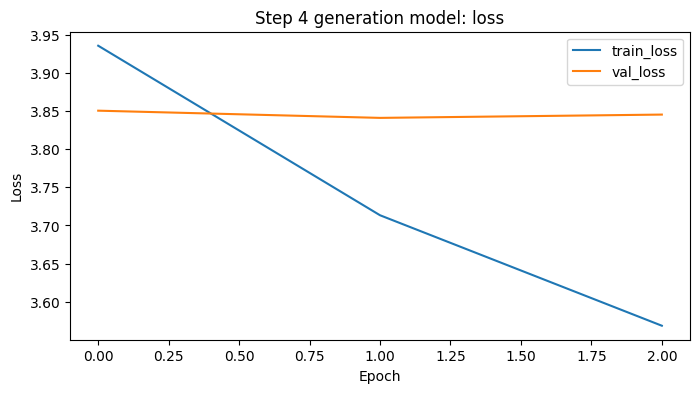

In [22]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.title("Step 4 generation model: loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [32]:
PROMPT_TO_INTERNAL_LABELS = {
    "History": ["Category: History - Modern (1750+)"],
    "Child Literature": ["Category: Children & Young Adult Reading"],
    "Adventure": ["Category: Adventure"],
    "Humour": ["Category: Humour"],
    "American Literature": ["Category: American Literature"],
    "Biography": ["Category: Biographies"],
}

def resolve_prompt_labels(prompt_labels):
    resolved = []
    for prompt in prompt_labels:
        if prompt in PROMPT_TO_INTERNAL_LABELS:
            resolved.extend(PROMPT_TO_INTERNAL_LABELS[prompt])
        elif prompt in all_labels:
            resolved.append(prompt)
        else:
            raise ValueError(
                f"Prompt '{prompt}' is not mapped to the generation/classifier label space."
            )
    return resolved

def build_generation_prompt(prompt_labels):
    internal_labels = resolve_prompt_labels(prompt_labels)
    labels_text = " | ".join(internal_labels)
    return f"labels: {labels_text}\ntext:", internal_labels


## Why human-readable prompts are mapped to internal labels

The generation prompts are intentionally written in a human-readable form such as
`History`, `Adventure`, and `Child Literature`. 

However, the generation model and the classifier from step 3 operate in the
internal label space of the prepared dataset, for example
`Category: History - Modern (1750+)` or
`Category: Children & Young Adult Reading`. Because these two naming systems are
not always identical, a mapping layer is needed.

This mapping serves two purposes:

- it keeps the prompts understandable and meaningful for the reader;
- it allows evaluation in terms of the exact label space used by the classifier.

This is more defensible than directly prompting with internal dataset labels,
because it separates the human prompt space from the technical label space.

In [33]:
def generate_text_from_labels(prompt_labels, max_new_tokens=GENERATION_MAX_NEW_TOKENS):
    prompt, internal_labels = build_generation_prompt(prompt_labels)

    tokenized = gen_tokenizer(prompt, return_tensors="tf")
    generated_ids = gen_model.generate(
        input_ids=tokenized["input_ids"],
        attention_mask=tokenized["attention_mask"],
        max_new_tokens=max_new_tokens,
        do_sample=True,
        temperature=0.7,
        top_k=40,
        top_p=0.9,
        repetition_penalty=1.2,
        no_repeat_ngram_size=3,
        pad_token_id=gen_tokenizer.pad_token_id,
        eos_token_id=gen_tokenizer.eos_token_id,
    )

    generated_text = gen_tokenizer.decode(generated_ids[0], skip_special_tokens=True)
    return generated_text, internal_labels


## Why these generation settings were chosen

Generation is done with stochastic decoding rather than greedy decoding. The aim is
to let the model produce varied continuations while still keeping the text readable.

- `temperature=0.7` reduces randomness compared with pure sampling;
- `top_k=40` and `top_p=0.9` limit sampling to plausible next-token candidates;
- `repetition_penalty=1.2` and `no_repeat_ngram_size=3` reduce repetitive output.

These values were chosen as practical defaults: they are strong enough to avoid very
repetitive continuations, but still flexible enough to show whether the model can
express category-related language patterns.

In [34]:
prompt_1 = ["History"]
prompt_2 = ["Adventure"]
prompt_3 = ["Child Literature"]
prompt_4 = ["History", "Adventure"]

generated_1, internal_1 = generate_text_from_labels(prompt_1)
generated_2, internal_2 = generate_text_from_labels(prompt_2)
generated_3, internal_3 = generate_text_from_labels(prompt_3)
generated_4, internal_4 = generate_text_from_labels(prompt_4)

print("=== Human prompt:", prompt_1, "===")
print("Resolved internal labels:", internal_1)
print(generated_1[:1200], "\n")

print("=== Human prompt:", prompt_2, "===")
print("Resolved internal labels:", internal_2)
print(generated_2[:1200], "\n")

print("=== Human prompt:", prompt_3, "===")
print("Resolved internal labels:", internal_3)
print(generated_3[:1200], "\n")

print("=== Human prompt:", prompt_4, "===")
print("Resolved internal labels:", internal_4)
print(generated_4[:1200])


=== Human prompt: ['History'] ===
Resolved internal labels: ['Category: History - Modern (1750+)']
labels: Category: History - Modern (1750+)
text: in the first place, and the two cities of Cairo were the capitals. At the beginning there was a great deal to be done for this purpose; but it was to follow that Egypt had been at last occupied by an independent state, which had been given its independence by some monarchs who, from 1807 until 1908 under King Mohammed, had established itself as one sovereign in the heartland, with the capital city of Cairo, and thence into the territory bordering on the Suez Canal, the latter being called the capital of the former. The king's authority extended to many provinces, and to several 

=== Human prompt: ['Adventure'] ===
Resolved internal labels: ['Category: Adventure']
labels: Category: Adventure
text: to be seen on the same day, he was at the first sight. It is a very interesting scene, and I have been in it for some time, and now you will see 

## Interpretation of the example generations

The examples above are meant as a qualitative inspection step. They show whether the
generated text is readable and whether the requested prompt seems to influence the
continuation.

Because generation is stochastic, a single example should not be treated as final
proof that a prompt always works or always fails. Instead, the examples are used to
inspect fluency, style, and obvious thematic signals before running a more explicit
classifier-based alignment check below.

### Analysis of generated outputs

The generated texts show varying levels of success depending on the prompt.

For the **History** prompt, the generated text demonstrates relatively strong thematic alignment. It contains references to real-world locations (e.g. Cairo, Suez Canal), political structures, and temporal markers, which are typical for historical narratives. The classifier prediction also matches a history-related category. This suggests that the model is capable of capturing domain-specific vocabulary and structure when the prompt is sufficiently well represented in the training data.

For the **Adventure** prompt, the output is syntactically valid but thematically weak. The text reads as generic narrative prose without clear elements of action, exploration, or risk that are characteristic of adventure literature. Although the classifier predicts the correct label, the semantic content does not strongly reflect the intended category. This indicates that classifier alignment alone is not a sufficient indicator of generation quality.

For the **Child Literature** prompt, the model performs best. The generated text uses simpler sentence structures, dialogue, and narrative elements involving children and family contexts. This aligns well with expectations for children’s literature. Both qualitative inspection and classifier prediction support strong prompt alignment in this case.

For the **multi-label prompt (History + Adventure)**, the result is partially successful. The generated text includes elements of travel and machinery (ship, crew, repairs), which can be associated with adventure, and some contextual realism that may relate to historical settings. However, the integration of both categories is not fully consistent. The model tends to emphasize one aspect more than the other rather than combining them in a balanced way.

Overall, these results show that:
- The model reliably generates syntactically plausible text.
- Prompt alignment is uneven and depends on how clearly the category is represented in the training data.
- Classifier-based evaluation provides useful but incomplete evidence, as correct labels do not always imply strong semantic alignment.

This supports the conclusion that the model has learned meaningful textual patterns, but its ability to control generation according to abstract category prompts remains limited.

In [ ]:
classifier_model = TFAutoModelForSequenceClassification.from_pretrained(
    MODEL_DIR / "bert_transformer_model"
)

classifier_tokenizer = AutoTokenizer.from_pretrained(CLASSIFIER_MODEL_NAME)

In [36]:
all_labels = sorted({label for labels in chunks_df["labels"] for label in labels})
print(all_labels)

['Category: Adventure', 'Category: American Literature', 'Category: Biographies', 'Category: British Literature', 'Category: Children & Young Adult Reading', 'Category: Essays, Letters & Speeches', 'Category: History - American', 'Category: History - Modern (1750+)', 'Category: Humour', 'Category: Novels']


In [37]:
def classify_text_with_step3_model(text, threshold=CLASSIFIER_THRESHOLD):
    encoded = classifier_tokenizer(
        text,
        padding="max_length",
        truncation=True,
        max_length=256,
        return_tensors="tf"
    )

    outputs = classifier_model(encoded)
    probs = tf.math.sigmoid(outputs.logits)[0].numpy()

    predicted_labels = [
        all_labels[i]
        for i, prob in enumerate(probs)
        if prob >= threshold
    ]

    return predicted_labels, probs

## Why the step 3 classifier is reused for evaluation

There is no perfect automatic metric here for checking whether generated text matches
the intended category prompt. For that reason, the classifier from step 3 is reused
as an approximate evaluator.

This choice is reasonable because that classifier was the strongest classification
model in the project. If it predicts labels that correspond to the intended prompt,
that provides evidence that the generated text still carries part of the desired
category signal.

At the same time, this evaluation must be interpreted carefully. The classifier is
not a ground-truth judge, and prompt names do not always match classifier labels
exactly. Therefore, the results below are treated as approximate evidence of prompt
alignment rather than absolute proof.

In [38]:
generated_samples = [
    (prompt_1, internal_1, generated_1),
    (prompt_2, internal_2, generated_2),
    (prompt_3, internal_3, generated_3),
    (prompt_4, internal_4, generated_4),
]

for human_prompts, expected_internal_labels, generated_text in generated_samples:
    predicted_labels, probs = classify_text_with_step3_model(generated_text)

    print("HUMAN PROMPTS:", human_prompts)
    print("EXPECTED INTERNAL LABELS:", expected_internal_labels)
    print("PREDICTED LABELS:", predicted_labels)
    print("TEXT PREVIEW:", generated_text[:400])
    print("-" * 80)


HUMAN PROMPTS: ['History']
EXPECTED INTERNAL LABELS: ['Category: History - Modern (1750+)']
PREDICTED LABELS: ['Category: History - Modern (1750+)']
TEXT PREVIEW: labels: Category: History - Modern (1750+)
text: in the first place, and the two cities of Cairo were the capitals. At the beginning there was a great deal to be done for this purpose; but it was to follow that Egypt had been at last occupied by an independent state, which had been given its independence by some monarchs who, from 1807 until 1908 under King Mohammed, had established itself as one 
--------------------------------------------------------------------------------
HUMAN PROMPTS: ['Adventure']
EXPECTED INTERNAL LABELS: ['Category: Adventure']
PREDICTED LABELS: ['Category: Children & Young Adult Reading', 'Category: Novels']
TEXT PREVIEW: labels: Category: Adventure
text: to be seen on the same day, he was at the first sight. It is a very interesting scene, and I have been in it for some time, and now you will see 

In [39]:
def evaluate_prompt_alignment(prompt_labels, predicted_labels):
    expected_internal_labels = resolve_prompt_labels(prompt_labels)
    matched_labels = [label for label in predicted_labels if label in expected_internal_labels]

    per_prompt_hits = {}
    for prompt in prompt_labels:
        prompt_targets = set(resolve_prompt_labels([prompt]))
        per_prompt_hits[prompt] = any(label in prompt_targets for label in predicted_labels)

    coverage_score = sum(per_prompt_hits.values()) / len(prompt_labels)

    return {
        "expected_internal_labels": expected_internal_labels,
        "matched_labels": matched_labels,
        "coverage_score": coverage_score,
        "fully_aligned": coverage_score == 1.0,
    }

evaluation_prompts = [
    ["History"],
    ["Adventure"],
    ["Child Literature"],
    ["History", "Adventure"],
    ["Adventure", "Child Literature"],
]

results = []

for prompt_labels in evaluation_prompts:
    generated_text, expected_internal_labels = generate_text_from_labels(prompt_labels)
    predicted_labels, probs = classify_text_with_step3_model(generated_text)
    alignment = evaluate_prompt_alignment(prompt_labels, predicted_labels)

    results.append({
        "human_prompts": ", ".join(prompt_labels),
        "expected_internal_labels": ", ".join(alignment["expected_internal_labels"]),
        "predicted_labels": ", ".join(predicted_labels),
        "matched_labels": ", ".join(alignment["matched_labels"]),
        "coverage_score": alignment["coverage_score"],
        "fully_aligned": alignment["fully_aligned"],
        "text_preview": generated_text[:250]
    })

results_df = pd.DataFrame(results)
results_df


,human_prompts,expected_internal_labels,predicted_labels,matched_labels,coverage_score,fully_aligned,text_preview
0,History,Category: History - Modern (1750+),"Category: American Literature, Category: Novels",,0.0,False,labels: Category: History - Modern (1750+)\nte...
1,Adventure,Category: Adventure,Category: Novels,,0.0,False,labels: Category: Adventure\ntext: at the end ...
2,Child Literature,Category: Children & Young Adult Reading,"Category: Children & Young Adult Reading, Cate...",Category: Children & Young Adult Reading,1.0,True,labels: Category: Children & Young Adult Readi...
3,"History, Adventure","Category: History - Modern (1750+), Category: ...",Category: History - Modern (1750+),Category: History - Modern (1750+),0.5,False,labels: Category: History - Modern (1750+) | C...
4,"Adventure, Child Literature","Category: Adventure, Category: Children & Youn...","Category: Children & Young Adult Reading, Cate...",Category: Children & Young Adult Reading,0.5,False,labels: Category: Adventure | Category: Childr...


## Conclusions from the generation outputs

The generation results show mixed performance.

The most successful prompt in the final evaluation is **Child Literature**. Its
generated sample reaches a coverage score of **1.0**, and the classifier predicts
`Category: Children & Young Adult Reading`, which is a direct match to the mapped
target label. This is the clearest evidence that the model can preserve a category
signal in generation.

The two mixed prompts, **History + Adventure** and **Adventure + Child Literature**,
each reach a coverage score of **0.5**. This means the model preserves part of the
requested category information, but not all of it. In practice, the model appears to
handle multi-label prompting only partially.

The weakest final results are the single-label prompts **History** and **Adventure**,
which both receive a coverage score of **0.0** in the sampled evaluation run. This
suggests that prompt control is not stable: the generated text may remain readable,
but the category-specific signal is sometimes too weak for the classifier to recover.

Taken together, these outputs support a balanced conclusion:
the model has learned enough structure to generate fluent text and sometimes reflect
the requested prompt, but category control remains inconsistent. The generation step
is therefore partially successful. It demonstrates transfer from the
Transformer-based setup in step 3, but it does not yet provide reliably controlled
text generation for every prompt.

Another important observation is that the outputs vary across runs because generation
uses sampling. This explains why a prompt may look convincing in one qualitative
example but score lower in the final evaluation table. For that reason, the
classifier-based results should be interpreted as approximate evidence, not as a
deterministic benchmark.